# ENCS5341 - Assignment 2
Data Integration, Cleaning, EDA and Insight Discovery

## 2. Data Integration

Each student's Assignment 1 submission is in `data/submissions/compressed-attachments/<student_id>/`.

Rules for picking one file per student:
- some students submitted more than once, so we take the **latest submission** (highest submission number)
- if a submission has both a CSV and an XLSX, we take the **XLSX** (in every case we checked they hold the same data, or the XLSX is the newer fix)
- ignore Mac junk (`__MACOSX`), Excel lock files and non-item files like `sources.csv`

In [1]:
import os
import glob
import pandas as pd
import numpy as np

DATA_DIR = "data/submissions/compressed-attachments"

In [2]:
# finds the one data file we use for a student
def pick_file(student_id):
    student_dir = os.path.join(DATA_DIR, student_id)
    candidates = []
    for f in glob.glob(os.path.join(student_dir, "**", "*"), recursive=True):
        name = os.path.basename(f).lower()
        if not name.endswith((".csv", ".xlsx")):
            continue
        if "__MACOSX" in f or name.startswith(".~lock") or name == "sources.csv":
            continue
        # submission number is the start of the first folder eg 3090683-1221464
        first_part = os.path.relpath(f, student_dir).split(os.sep)[0]
        submission = int(first_part.split("-")[0])
        is_xlsx = name.endswith(".xlsx")
        candidates.append((submission, is_xlsx, f))
    # latest submission first, then xlsx over csv
    candidates.sort(reverse=True)
    return candidates[0][2]

students = sorted(os.listdir(DATA_DIR))
chosen = {sid: pick_file(sid) for sid in students}
print(len(chosen), "students")

120 students


### Files that need special loading

| Student | Problem | Fix |
|---|---|---|
| 1210784 | space after every comma so quotes are ignored | `skipinitialspace=True` |
| 1231100 | commas inside descriptions with no quotes | custom split (last 5 fields are always category, age, condition, price, currency) |
| 1220226 | table starts on row 3 | `header=2` |
| 1230313 | student name and ID above the table | `header=5` |
| 1230358 | one empty row above the header | `header=1` |

1230049 has a `;` separated CSV but the XLSX gets picked anyway. Empty `Unnamed` columns (eg 1231661) are dropped after loading.

Rows with no item ID and no title are also dropped. These are not items: 1230656 typed their name and ID under the table, and 1230773 has a row that only contains spaces.

In [3]:
# 1231100 has unquoted commas so we split each line ourselves
def load_1231100(path):
    with open(path, encoding="utf-8", errors="replace") as f:
        lines = [line.strip() for line in f if line.strip()]
    header = lines[0].split(",")
    rows = []
    for line in lines[1:]:
        parts = line.split(",")
        middle = parts[2:-5]  # title + description
        # item_014 title has a comma in it too
        if parts[0] == "item_014":
            title = middle[0] + "," + middle[1]
            desc = ",".join(middle[2:])
        else:
            title = middle[0]
            desc = ",".join(middle[1:])
        rows.append([parts[0], parts[1], title, desc] + parts[-5:])
    return pd.DataFrame(rows, columns=header)


def read_csv_any(path, **kwargs):
    try:
        return pd.read_csv(path, **kwargs)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin1", **kwargs)


excel_header_row = {"1220226": 2, "1230313": 5, "1230358": 1}

def load_student(student_id, path):
    if student_id == "1231100":
        df = load_1231100(path)
    elif path.lower().endswith(".xlsx"):
        df = pd.read_excel(path, header=excel_header_row.get(student_id, 0))
    elif student_id == "1210784":
        df = read_csv_any(path, skipinitialspace=True)
    else:
        df = read_csv_any(path)
    # drop fully empty rows and columns (leftovers from excel)
    df = df.dropna(how="all").dropna(axis=1, how="all")
    df.columns = [str(c).strip() for c in df.columns]
    # drop junk rows with no id and no title (eg a name typed under the table)
    key_cols = [c for c in df.columns if c.lower() in ("item id", "item_id", "id", "title")]
    filled = df[key_cols].notna() & (df[key_cols].astype(str).apply(lambda c: c.str.strip()) != "")
    df = df[filled.any(axis=1)].copy()
    df["student_id"] = student_id
    df["source_file"] = os.path.relpath(path, DATA_DIR)
    return df

In [4]:
# load everyone, keep each student's table separate for now
frames = {}
for sid, path in chosen.items():
    frames[sid] = load_student(sid, path)

rows_per_student = pd.Series({sid: len(df) for sid, df in frames.items()})
print("students loaded:", len(frames))
print("total rows:", rows_per_student.sum())
print("students without 15 rows:")
print(rows_per_student[rows_per_student != 15])

students loaded: 120
total rows: 1801
students without 15 rows:
1230521    16
dtype: int64


### Standard column names

Students named the same columns in about 30 different ways (`Item photo`, `image_file`, `Age (years)`, `condition(1-5)` ...). Everything is renamed to one set:

`item_id, photo, title, description, category, age, condition, price, currency`

Only the names change here, not the values.

In [5]:
STANDARD_COLS = ["item_id", "photo", "title", "description", "category",
                 "age", "condition", "price", "currency"]

# maps any student's column name to our standard name
def standard_name(col):
    c = col.lower().strip()
    if c in ("item id", "item_id", "id"):
        return "item_id"
    if "photo" in c or "image" in c:  # check before age since image has "age" in it
        return "photo"
    if c.startswith("descr"):  # one student wrote Descreption
        return "description"
    if "age" in c:
        return "age"
    if c.startswith("condition"):
        return "condition"
    if c in ("title", "category", "price", "currency"):
        return c
    return col  # leave unknown columns alone so we can spot them

for sid in frames:
    frames[sid] = frames[sid].rename(columns=standard_name)

# check every student now has the standard columns and nothing weird
for sid, df in frames.items():
    missing = [c for c in STANDARD_COLS if c not in df.columns]
    extra = [c for c in df.columns if c not in STANDARD_COLS + ["student_id", "source_file"]]
    if missing or extra:
        print(sid, "missing:", missing, "extra:", extra)

1210482 missing: ['photo'] extra: []
1210784 missing: ['photo'] extra: []
1211312 missing: ['age'] extra: []
1220031 missing: ['item_id'] extra: []
1220161 missing: ['photo'] extra: []
1220874 missing: ['age'] extra: []
1221419 missing: ['currency'] extra: []
1222148 missing: ['photo'] extra: []
1230062 missing: ['photo'] extra: []
1230093 missing: ['photo'] extra: []
1230271 missing: ['age'] extra: []
1230318 missing: [] extra: ['Unnamed: 10']
1230656 missing: [] extra: ['link']


### Merge into one dataset

- keep only the standard columns plus `student_id` (drops `link` from 1230656 and a name signature column from 1230318)
- columns a student never filled (eg photo, or an all blank age) just come out empty
- item IDs like `item_001` repeat across students, so `uid` = `student_id` + `item_id` is the unique key
- 1220031 has no item ID column, so their IDs are numbered `item_001`... in file order
- values are kept exactly as submitted, type fixes happen in cleaning

In [6]:
tables = []
for sid, df in frames.items():
    df = df.copy()
    # 1220031 has no ids so number them in file order
    if "item_id" not in df.columns:
        df["item_id"] = [f"item_{i:03d}" for i in range(1, len(df) + 1)]
    # add any standard column the student didnt have as empty
    df = df.reindex(columns=["student_id"] + STANDARD_COLS)
    tables.append(df)

raw = pd.concat(tables, ignore_index=True)
raw["item_id"] = raw["item_id"].astype(str).str.strip()
raw.insert(0, "uid", raw["student_id"] + "_" + raw["item_id"])

# uid has to be unique
dupes = raw[raw["uid"].duplicated(keep=False)]
print("duplicate uids:", len(dupes))
if len(dupes) > 0:
    print(dupes[["uid", "title"]])

# utf-8-sig so excel shows the arabic text properly
raw.to_csv("marketplace_raw.csv", index=False, encoding="utf-8-sig")

print("observations:", len(raw))
print("students:", raw["student_id"].nunique())
print("categories (as written, before cleaning):", raw["category"].nunique())
raw.head()

duplicate uids: 0
observations: 1801
students: 120
categories (as written, before cleaning): 123


,uid,student_id,item_id,photo,title,description,category,age,condition,price,currency
0,1210482_1,1210482,1,NaN,Tesla Model 3,"standard range with 21,867 miles on it. Deep B...",Cars,4,4,28868,dollar
1,1210482_2,1210482,2,NaN,Mercedes-Benz AMG GT 63 4MATIC,22025 miles on it. Obsidian Black Metallic ext...,Cars,7,4,79412,dollar
2,1210482_3,1210482,3,NaN,Lexus LX 600 Luxury,11956 miles on it. Eminent White Pearl exterio...,Cars,3,5,90451,dollar
3,1210482_4,1210482,4,NaN,Crate & Barrel Unwind Green Velvet 2 Seater Sofa,Brand: Crate & Barrel. Collection: Unwind. Con...,Furniture,3,4,750,dollar
4,1210482_5,1210482,5,NaN,Drexel Heritage 1980s Postmodern Curved Sofa F...,Brand: Drexel. Condition: Used - Age-worn: Has...,Furniture,40,2,450,dollar


### Image linking check

For each item we look for its photo inside the same submission folder the data file came from:
- **linked**: the file named in `photo` exists
- **wrong extension**: same name exists but with another extension (eg `.jpeg` written, `.png` on disk)
- **matched by id**: no `photo` value, but a file named after the item ID exists (eg `item_001.jpg`)
- **missing**: nothing found

In [7]:
import re

IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".avif", ".heic", ".gif")

# all image files in a student's chosen submission, keyed by lowercase name
def image_files(student_id):
    student_dir = os.path.join(DATA_DIR, student_id)
    first_part = os.path.relpath(chosen[student_id], student_dir).split(os.sep)[0]
    folder = os.path.join(student_dir, first_part)
    # 1220588 sent the csv and the images as two separate uploads
    if not os.path.isdir(folder):
        folder = student_dir
    files = {}
    for f in glob.glob(os.path.join(folder, "**", "*"), recursive=True):
        if f.lower().endswith(IMAGE_EXTS) and "__MACOSX" not in f:
            files[os.path.basename(f).lower()] = f
    return files


# first number in a name eg item-01.jpg -> 1, 0001.png -> 1, Picture -> None
def item_number(text):
    found = re.findall(r"\d+", str(text))
    if found:
        return int(found[0])
    return None


def photo_status(row, files):
    stems = {os.path.splitext(name)[0]: name for name in files}
    numbers = {item_number(name) for name in files}
    photo = row["photo"]
    has_photo = pd.notna(photo) and str(photo).strip() != ""
    if has_photo:
        name = str(photo).strip().replace("\\", "/").split("/")[-1].lower()
        if name in files:
            return "linked"
        if os.path.splitext(name)[0] in stems:
            return "wrong extension"
    elif row["item_id"].lower() in stems:
        return "matched by id"
    # fallback: match on the item number (photo name first, then item id)
    num = item_number(photo) if has_photo else None
    if num is None:
        num = item_number(row["item_id"])
    if num is not None and num in numbers:
        return "matched by number"
    return "missing"


all_files = {sid: image_files(sid) for sid in raw["student_id"].unique()}
img_status = raw.apply(lambda r: photo_status(r, all_files[r["student_id"]]), axis=1)

print(img_status.value_counts())
print()
print("still missing:")
print(raw.loc[img_status == "missing", ["uid", "photo"]])

linked               1507
wrong extension       124
matched by number     108
matched by id          60
missing                 2
Name: count, dtype: int64

still missing:
                   uid         photo
704   1230011_item_015  item_015.png
1045  1230318_item_011  item_011.jpg


In [8]:
# section 2 numbers for the report
linked_ok = img_status.isin(["linked", "wrong extension", "matched by id", "matched by number"]).sum()

print("observations:", len(raw))
print("students:", raw["student_id"].nunique())
print("categories as written:", raw["category"].nunique())
print("categories ignoring case/spaces:", raw["category"].astype(str).str.strip().str.lower().nunique())
print("duplicate uids:", raw["uid"].duplicated().sum())
print(f"items linked to a photo: {linked_ok} / {len(raw)} ({linked_ok / len(raw):.1%})")

observations: 1801
students: 120
categories as written: 123
categories ignoring case/spaces: 97
duplicate uids: 0
items linked to a photo: 1799 / 1801 (99.9%)


### Section 2 summary

| | |
|---|---|
| Observations | 1,801 items |
| Students | 120 (119 with 15 items, 1 with 16) |
| Categories | 123 as written, 97 ignoring case and spaces, 11 after cleaning (Section 3) |
| Unique item IDs | yes, `uid` = student ID + item ID, 0 duplicates |
| Images linked | 1,799 / 1,801 (99.9%) |

Integration decisions:
- 14 students had more than one file, we kept the latest submission (XLSX over CSV in the same submission)
- 5 files needed special loading (see table above)
- 2 junk rows removed (a name signature and a row of spaces), plus 2 extra columns (`link` and a name signature)
- 1220031 had no item IDs, so they were numbered in file order
- data types: values are kept exactly as submitted here (eg price `1,200`, age `2 years`) so the raw file stays unchanged. They are turned into numbers in Section 3
- 124 photos only differed in extension (eg `.jpg` vs `.jpeg`) and 108 were matched by the number in the filename (eg `item-01.jpg`, `0001.png`). These were matched by name, not checked visually
- 2 items have no matching photo (`1230011_item_015`, `1230318_item_011`). Both folders contain an unrenamed screenshot or WhatsApp image that is probably the missing photo

## 3. Data Quality Assessment and Cleaning

We work on a copy called `df`, so `raw` (and `marketplace_raw.csv`) stays unchanged.

### Missing values
Two kinds of missing:
- **blank**: the cell is empty
- **placeholder text**: the student wrote something like `Unknown`, `N/A` or `-` instead of a value

In [9]:
df = raw.copy()

PLACEHOLDERS = ["unknown", "n/a", "na", "none", "-", "?", "not known", "nan"]

cols = STANDARD_COLS
text = df[cols].astype(str).apply(lambda c: c.str.strip().str.lower())
blank = df[cols].isna() | (text == "")
placeholder = ~blank & text.isin(PLACEHOLDERS)

missing = pd.DataFrame({
    "blank": blank.sum(),
    "placeholder": placeholder.sum(),
})
missing["total"] = missing["blank"] + missing["placeholder"]
missing["percent"] = (missing["total"] / len(df) * 100).round(2)
missing

,blank,placeholder,total,percent
item_id,0,0,0,0.00
photo,90,0,90,5.00
title,0,0,0,0.00
description,1,0,1,0.06
category,1,0,1,0.06
age,373,2,375,20.82
condition,15,5,20,1.11
price,32,1,33,1.83
currency,23,12,35,1.94


### Duplicates
`uid` is already unique, so here we look for the **same item entered twice** under different IDs:
1. exact duplicate rows (everything the same except the ID and photo)
2. same title twice by the same student
3. same title + description across different students (eg two students used the same online listing)

Text is compared lowercased and trimmed.

In [10]:
print("duplicate uids:", df["uid"].duplicated().sum())

# lowercase trimmed copy just for comparing
cmp = df.astype(str).apply(lambda c: c.str.strip().str.lower())

# 1. exact duplicate rows ignoring the id and photo
value_cols = ["student_id", "title", "description", "category", "age", "condition", "price", "currency"]
exact = cmp.duplicated(subset=value_cols, keep=False)
print("exact duplicate rows:", exact.sum())

# 2. same title twice by one student
same_student = cmp.duplicated(subset=["student_id", "title"], keep=False)
print("same title within a student:", same_student.sum())

# 3. same title + description by different students
across = cmp.duplicated(subset=["title", "description"], keep=False) & ~same_student
print("same title + description across students:", across.sum())

df.loc[exact | same_student | across, ["uid", "title", "price", "currency"]].sort_values("title")

duplicate uids: 0
exact duplicate rows: 0
same title within a student: 2
same title + description across students: 0


,uid,title,price,currency
1331,1230696_item_011,Vintage brass Scales of Justice beam balance s...,57.86,USD
1332,1230696_item_012,Vintage brass Scales of Justice beam balance s...,99.79,USD


No exact duplicates. The same-title pair inside 1230696 is **not** a duplicate: item_011's description is a different scale, so the student copied the wrong title. Both are kept.

But some items have the **same title and the same price** from different students. These look like the same online listing collected by more than one student (descriptions differ because each student wrote their own). Counting them twice would double count that listing, so:
- rule: same title (ignoring case and spaces) + same price + different students = duplicate
- we keep the first one and drop the rest
- every duplicate group is saved to `reports/duplicates.csv` with what happened to each row

In [11]:
# same title + same price from different students
key = pd.DataFrame({
    "title": cmp["title"],
    "price": pd.to_numeric(df["price"], errors="coerce"),  # so 1000 and 1000.0 match
})
has_price = key["price"].notna()
listing_dupe = has_price & key.duplicated(subset=["title", "price"], keep=False) & ~same_student

dupes = df[listing_dupe].copy()
dupes["group"] = key[listing_dupe].groupby(["title", "price"]).ngroup() + 1
dupes["action"] = "kept"
dropped = listing_dupe & key.duplicated(subset=["title", "price"], keep="first")
dupes.loc[dropped[listing_dupe], "action"] = "dropped"

# save the list so its easy to check
os.makedirs("reports", exist_ok=True)
dupes = dupes.sort_values(["group", "uid"])
dupes[["group", "action", "uid", "student_id", "title", "age", "condition", "price", "currency", "description"]] \
    .to_csv("reports/duplicates.csv", index=False, encoding="utf-8-sig")

df = df[~dropped].reset_index(drop=True)
print("duplicate groups:", dupes["group"].nunique())
print("rows dropped:", dropped.sum())
print("rows left:", len(df))
dupes[["group", "action", "uid", "title", "price", "currency"]]

duplicate groups: 5
rows dropped: 6
rows left: 1795


,group,action,uid,title,price,currency
443,1,kept,1221137_item_009,Excellent Sport Treadmill,900,ILS
931,1,dropped,1230197_item_002,Excellent Sport Treadmill,900,ILS
61,2,kept,1211312_item_002,Fossil Q Wander Smartwatch,300,ILS
692,2,dropped,1230011_item_003,Fossil Q Wander Smartwatch,300,ILS
355,3,kept,1220782_item_011,KUIKMA PR React Soft padel racket,300,NIS
572,3,dropped,1221682_item_003,KUIKMA PR React Soft Padel Racket,300,ILS
1631,3,dropped,1231286_item_011,KUIKMA PR React Soft Padel Racket,300,ILS
98,4,kept,1212974_1212974_009,Sharp 9 kg washing machine,1000,ILS
348,4,dropped,1220782_item_004,Sharp 9 kg washing machine,1000,NIS
354,5,kept,1220782_item_010,York Patrol 80100 treadmill,1000,NIS


### Price and currency formats

**Price**: 81 prices were stored as text. Most just had thousands commas (`1,589.00`, `350,000`, `1,000.`), these are converted to numbers. Blank or `unknown` prices become missing (not 0).

**Currency**: the same currency was written in different ways. Everything is trimmed, uppercased and mapped to its ISO code:
- `NIS`, `Shekel`, `₪`, `ils` -> `ILS`
- `dollar`, `usd` -> `USD`
- `Unknown` or blank -> missing

Other codes (GBP, EUR, CHF, JOD, AED ...) are already proper codes and are kept. Converting everything to one currency comes later.

In [12]:
# price: drop thousands commas then make it a number, anything else becomes NaN
price_text = df["price"].astype(str).str.strip().str.replace(",", "")
df["price"] = pd.to_numeric(price_text, errors="coerce")

# currency: same currency written different ways
CURRENCY_MAP = {"NIS": "ILS", "SHEKEL": "ILS", "₪": "ILS", "DOLLAR": "USD",
                "UNKNOWN": np.nan, "NAN": np.nan, "": np.nan}
cur = df["currency"].astype(str).str.strip().str.upper()
df["currency"] = cur.replace(CURRENCY_MAP)

print("price missing:", df["price"].isna().sum())
print("currency missing:", df["currency"].isna().sum())
print("price but no currency:", (df["price"].notna() & df["currency"].isna()).sum())
print()
print(df["currency"].value_counts(dropna=False))

price missing: 33
currency missing: 35
price but no currency: 10

currency
ILS    1212
USD     409
GBP      54
NaN      35
EUR      23
CHF      19
JOD      10
AED       9
SGD       7
EGP       6
SAR       4
TWD       2
LYD       1
IQD       1
SEK       1
AUD       1
INR       1
Name: count, dtype: int64


### Convert all prices to ILS

Prices are in 16 currencies, so they can't be compared directly. A new column `price_ils` holds every price in shekels. The original `price` and `currency` are kept as submitted.

One fixed rate per currency is used for every item, as of **20 Nov 2026**:
- USD (3.28), EUR (3.61, ECB reference) and GBP (4.31) were checked against online rates for that week
- JOD, AED and SAR are pegged to the dollar, so their rates follow from the USD rate
- the remaining small currencies (CHF, SGD, EGP, TWD, AUD, SEK, LYD, IQD, INR: 42 items) use approximate rates

Items with no currency (10 from 1221419) get no `price_ils`.

In [13]:
# 1 unit of each currency in ILS, rates as of 20 Nov 2026
# USD EUR GBP checked online, JOD AED SAR follow from USD (pegged), the rest are approximate
TO_ILS = {
    "ILS": 1.0, "USD": 3.28, "EUR": 3.61, "GBP": 4.31, "CHF": 4.15,
    "JOD": 4.63, "AED": 0.89, "SAR": 0.875, "SGD": 2.60, "AUD": 2.20,
    "SEK": 0.35, "TWD": 0.11, "EGP": 0.068, "LYD": 0.62, "INR": 0.039,
    "IQD": 0.0026,
}

print("currencies with no rate:", set(df["currency"].dropna()) - set(TO_ILS))
df["price_ils"] = (df["price"] * df["currency"].map(TO_ILS)).round(2)

print("price_ils filled:", df["price_ils"].notna().sum(), "/", len(df))
df.groupby("currency")["price_ils"].median().round(1)

currencies with no rate: set()
price_ils filled: 1752 / 1795


currency
AED     489.5
AUD     143.0
CHF     747.0
EGP     244.8
EUR     649.8
GBP     280.2
ILS     100.0
INR     585.0
IQD    1170.0
JOD     393.6
LYD    4216.0
SAR     328.1
SEK    1085.0
SGD      91.0
TWD    2513.1
USD     196.8
Name: price_ils, dtype: float64

### Category names

97 different category spellings. Assignment 1 suggested 10 categories (Electronics, Furniture, Clothing and accessories, Books, Sports equipment, Toys and games, Kitchen and household items, Tools, Musical instruments, Other used products), so everything is mapped back to those, plus 1 extra group:
- **Vehicles** (cars, motorcycles, electric bikes, 38 items in the final data after the fixes below): median price around 49,000 ILS, way above every other category, so mixing them into another category would distort it

Rules:
- spelling variants go to their category (`clothing & accessories` -> Clothing and accessories)
- sub categories go to their parent (`laptops`, `keyboards` -> Electronics, `refrigerators` -> Kitchen and household items)
- home decor, rugs and storage -> Furniture
- small groups that don't fit anywhere (stationery, personal care, pet and baby items, antiques, car accessories ...) -> Other used products. Car accessories (one set of car floor mats) are not vehicles, so they don't go in Vehicles

The full mapping is saved in `reports/category_mapping.csv`.

In [14]:
# final category -> every lowercase spelling that goes into it
CATEGORY_GROUPS = {
    "Electronics": ["electronics", "electronics and tech", "electronics and accessories", "electronics & gaming",
                    "laptops", "phones", "mobile phones", "smartphone", "smartwatch", "camera",
                    "cameras & photography", "keyboards", "computer monitors", "mobile & tablet accessories",
                    "phone accessories", "video game console"],
    "Clothing and accessories": ["clothing and accessories", "clothing & accessories", "clothing", "clothes",
                                 "clothing & footwear", "shoes", "footwear", "accessories", "bags", "bags & accessories",
                                 "bags and accessories", "watches & jewelry", "wallets & small leather goods"],
    "Kitchen and household items": ["kitchen and household items", "kitchen & household", "kitchen and household",
                                    "kitchen & household items", "kitchen and household item", "kitchen", "kitchen items",
                                    "household & everyday items", "household appliances", "office & household",
                                    "microwave ovens", "gas cookers and ovens", "refrigerators"],
    "Furniture": ["furniture", "furniture & home decor", "home decor", "home décor", "decor", "art and decor",
                  "rugs and carpets", "wardrobes and storage cabinets", "dining tables and chair sets"],
    "Books": ["books", "book", "science textbooks"],
    "Sports equipment": ["sports equipment", "sports equipments", "sports", "fitness equipment",
                         "camping equipment", "bicycle"],
    "Toys and games": ["toys and games", "toys & games", "toys", "games", "games and toys", "video game", "chess"],
    "Musical instruments": ["musical instruments", "musical instrument", "acoustic guitars"],
    "Tools": ["tools", "cordless drills"],
    "Vehicles": ["vehicles", "cars", "car", "motorcycles", "electric bicycles"],
    "Other used products": ["other used products", "other", "stationery", "stationery and office supplies",
                            "office and school supplies", "personal care", "health & personal care",
                            "beauty and personal care", "health", "pet supplies", "baby products", "strollers",
                            "antiques", "collectibles", "commercial equipment", "agriculture", "arts and crafts",
                            "garden and outdoor gear", "automotive accessories"],
}

# flip it into spelling -> category
CATEGORY_MAP = {}
for final, spellings in CATEGORY_GROUPS.items():
    for s in spellings:
        CATEGORY_MAP[s] = final

cat_lower = df["category"].astype(str).str.strip().str.lower()
print("spellings with no mapping:", sorted(set(cat_lower) - set(CATEGORY_MAP) - {"nan"}))

# save which spelling went where, with counts
mapping = cat_lower.value_counts().rename_axis("written_as").reset_index(name="items")
mapping["category"] = mapping["written_as"].map(CATEGORY_MAP)
mapping.sort_values(["category", "items"], ascending=[True, False]) \
    .to_csv("reports/category_mapping.csv", index=False, encoding="utf-8-sig")

df["category"] = cat_lower.map(CATEGORY_MAP)
print("categories now:", df["category"].nunique())
df["category"].value_counts(dropna=False)

spellings with no mapping: []
categories now: 11


category
Electronics                    404
Clothing and accessories       277
Kitchen and household items    252
Furniture                      206
Books                          145
Sports equipment               135
Toys and games                 110
Other used products             85
Tools                           73
Musical instruments             72
Vehicles                        35
NaN                              1
Name: count, dtype: int64

### Age and condition formats

Assignment 1 asked for age as a number of years and condition as a 1-5 score, with blanks for unknown numbers. Some students typed text instead.

**Age** (40 text values from 7 students):
- `2 years`, `1 year` -> the number
- `2 months`, `3 moths` -> months / 12 (eg 6 months = 0.5)
- `Unknown`, `Unkown` -> missing

**Condition** (33 text values), using the Assignment 1 scale:
- `4 — Good` -> 4 (number at the start is used)
- `like new` 5, `good` 4, `fair` 3, `poor` 2, `very poor` 1
- `Unknown` -> missing

Values that are numbers but out of range (eg condition 9) are left for the invalid values check.

In [15]:
# age: number of years, months get divided by 12, anything else is missing
def clean_age(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    match = re.match(r"([\d.]+)\s*([a-z]*)", text)
    if not match:
        return np.nan  # unknown, unkown ...
    number = float(match.group(1))
    if match.group(2).startswith("mo"):  # month, months, moths
        number = number / 12
    return round(number, 2)


# condition: assignment 1 scale
CONDITION_WORDS = {"like new": 5, "good": 4, "fair": 3, "poor": 2, "very poor": 1}

def clean_condition(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    match = re.match(r"\d+(\.\d+)?", text)
    if match:  # 4, 4.0, 4 — good
        return float(match.group())
    return CONDITION_WORDS.get(text, np.nan)


age_before = df["age"].notna().sum()
cond_before = df["condition"].notna().sum()
df["age"] = df["age"].apply(clean_age)
df["condition"] = df["condition"].apply(clean_condition)

print("age: had a value", age_before, "-> numeric", df["age"].notna().sum())
print("condition: had a value", cond_before, "-> numeric", df["condition"].notna().sum())
print()
print(df[["age", "condition"]].describe().round(2))
print()
print(df["condition"].value_counts(dropna=False).sort_index())

age: had a value 1426 -> numeric 1414
condition: had a value 1780 -> numeric 1776

           age  condition
count  1414.00    1776.00
mean      8.33       3.74
std      16.68       0.97
min       0.00       1.00
25%       1.00       3.00
50%       3.00       4.00
75%       7.00       4.00
max     216.00       9.00

condition
1.0     41
2.0    144
3.0    451
4.0    752
5.0    387
9.0      1
NaN     19
Name: count, dtype: int64


### Invalid values

Values that can't be right (or need a closer look):
- **price** negative or 0
- **condition** outside 1-5 or not a whole number
- **age** negative, or over 50 years (possible for antiques, so each one is checked by reading the title and description)

Nothing is changed in this cell, it only lists them.

In [16]:
bad_price = df["price"] <= 0
bad_condition = df["condition"].notna() & (~df["condition"].between(1, 5) | (df["condition"] % 1 != 0))
bad_age = (df["age"] < 0) | (df["age"] > 50)

print("price <= 0:", bad_price.sum())
print("condition outside 1-5 or not whole:", bad_condition.sum())
print("age < 0 or > 50:", bad_age.sum())

check_cols = ["uid", "title", "category", "age", "condition", "price", "currency"]
df.loc[bad_price | bad_condition | bad_age, check_cols].sort_values("age", ascending=False)

price <= 0: 1
condition outside 1-5 or not whole: 1
age < 0 or > 50: 46


,uid,title,category,age,condition,price,currency
1123,1230482_item_003,"Antique Hand-Painted Dome-Top Wooden Box, Earl...",Other used products,216.0,3.0,195.00,USD
792,1230099_item_001,Large Red Copper Teapot,Kitchen and household items,150.0,5.0,400.00,ILS
708,1230014_item_007,1850-1885 S. Kirk & Son Co. Sterling Silver Be...,Kitchen and household items,126.0,2.0,360.00,USD
716,1230014_item_015,Fine Genuine Handmade Middle Eastern Pictorial...,Other used products,126.0,4.0,6495.00,USD
486,1221305_item_008,Edwardian platinum sapphire and diamond ring,Clothing and accessories,116.0,5.0,5259.80,USD
77,1212312_item_003,Edwardian 1911 Drafting Set Hull School Prize ...,Other used products,115.0,4.0,55.00,GBP
1326,1230696_item_010,Antique Salter’s,Kitchen and household items,106.0,3.0,79.00,USD
818,1230100_12,Used Natural History of Man Book,Books,102.0,4.0,140.00,ILS
795,1230099_item_004,Charcoal Iron,Kitchen and household items,100.0,4.0,300.00,ILS
715,1230014_item_014,Antique German Silver Mesh Purse / Evening Bag...,Clothing and accessories,100.0,4.0,65.00,USD


Decisions after checking each item:
- **46 items older than 50 years**: all are antiques or vintage items and the title or description backs up the age (eg "Early 19th Century" box at 216 years, "1954 Fender Stratocaster" at 72). Kept
- **price 0** (1220064_item_003, electric cooker): the description says it is offered free, so 0 is the real price. Kept
- **age 0** (16 items): brand new or under a month old, plausible. Kept
- **condition 9** (1230501_item_009, PS5): outside the 1-5 scale, probably a typo. The seller says "in perfect condition" and the photo shows a clean console with 2 controllers and cables, which matches 5 (Like New) on the Assignment 1 scale. Set to 5

In [17]:
# ps5 condition 9 is a typo, seller says perfect condition -> 5
df.loc[df["uid"] == "1230501_item_009", "condition"] = 5

print("condition outside 1-5 now:", (~df["condition"].dropna().between(1, 5)).sum())
df.loc[df["uid"] == "1230501_item_009", ["uid", "title", "condition"]]

condition outside 1-5 now: 0


,uid,title,condition
1159,1230501_item_009,Used play station 5,5.0


One more duplicate showed up while reading the old items: `1220433_7` "The Natural History of Man" and `1230100_12` "Used Natural History of Man Book" are both the rare 1924 second edition at 140 ILS with near identical descriptions. A third copy is `1230509_item_009`, titled in Arabic ("كتاب تاريخ الإنسان الطبيعي", The Natural History of Man), also the 1924 second edition at 140 ILS. The titles are worded differently (and one is in another language), so the same title + price rule missed them. They are added to `reports/duplicates.csv` as group 6, `1230100_12` is kept and `1220433_7` and `1230509_item_009` are dropped.

In [18]:
# same 1924 book listed by three students with different titles (one in arabic)
book = df[df["uid"].isin(["1230100_12", "1220433_7", "1230509_item_009"])].copy()
book["group"] = dupes["group"].max() + 1
book["action"] = np.where(book["uid"] == "1230100_12", "kept", "dropped")
dupes = pd.concat([dupes, book], ignore_index=True)

dupes[["group", "action", "uid", "student_id", "title", "age", "condition", "price", "currency", "description"]] \
    .to_csv("reports/duplicates.csv", index=False, encoding="utf-8-sig")

df = df[~df["uid"].isin(["1220433_7", "1230509_item_009"])].reset_index(drop=True)
print("rows left:", len(df))
dupes[["group", "action", "uid", "title", "price", "currency"]].tail(3)

rows left:

 1793


,group,action,uid,title,price,currency
11,6,dropped,1220433_7,The Natural History of Man,140.0,ILS
12,6,kept,1230100_12,Used Natural History of Man Book,140.0,ILS
13,6,dropped,1230509_item_009,كتاب تاريخ الإنسان الطبيعي,140.0,ILS


### Fixes found while reviewing the outliers

These came up when reading the most expensive items per category. They are applied here, before the outlier check, so the outlier list reflects the fixed data.

- **6 cars filed under Other used products** (Mercedes GLA AMG 2016, Kia, Hyundai Tucson, Mercedes GLA 2020, BMW 520i 2014, Mercedes C250 2013) -> moved to Vehicles. The kids ride-on Mercedes stays in Toys and games
- **Same BMW from 3 students**: `1220433_8`, `1230100_7` and `1230746_10` are all a 2022 BMW 545e, 4 years old, 350,000 ILS. Added to `reports/duplicates.csv` as group 7, `1220433_8` is kept (first in file order, like groups 1-5)
- **Chicken farm** (`1230746_11`, 800,000 ILS): a farm building is property, not a second-hand item, so it is outside what Assignment 1 asked for. Dropped

In [19]:
# cars that students put under other
cars = ["1220357_item_007", "1220893_item_012", "1221769_item_014",
        "1221960_item_005", "1230127_item_014", "1230588_item_010"]
df.loc[df["uid"].isin(cars), "category"] = "Vehicles"

# same bmw from 3 students, keep the first
bmw_ids = ["1220433_8", "1230100_7", "1230746_10"]
bmw = df[df["uid"].isin(bmw_ids)].copy()
bmw["group"] = dupes["group"].max() + 1
bmw["action"] = np.where(bmw["uid"] == "1220433_8", "kept", "dropped")
dupes = pd.concat([dupes, bmw], ignore_index=True)
dupes[["group", "action", "uid", "student_id", "title", "age", "condition", "price", "currency", "description"]] \
    .to_csv("reports/duplicates.csv", index=False, encoding="utf-8-sig")

# drop the 2 bmw copies and the chicken farm
drop_ids = ["1230100_7", "1230746_10", "1230746_11"]
df = df[~df["uid"].isin(drop_ids)].reset_index(drop=True)

print("rows left:", len(df))
print("vehicles:", (df["category"] == "Vehicles").sum())

rows left: 1790
vehicles: 39


### Duplicates written in another language

The title + price rule compares text, so it cannot match an item written in Arabic with the same item written in English. We listed the 32 items that have Arabic text, compared them with other students' items that have the same price and category, then compared the photos. 3 more duplicates were confirmed, in each pair both students used the same photo:

- **Bicycle:** `1230093_8` "بسكليت" and `1222192_item_014` "Old Racing Bicycle", 120 ILS. The English description is a translation of the Arabic one
- **Chicco baby crib:** `1230093_3` "سرير تشيكو بيبي" and `1220357_item_013` "Chicco Next2Me Baby Bedside Crib", 600 ILS
- **Pool table:** `1230656_item_004` "Billiard table" and `1220357_item_009` "Used American 8-Ball Pool Table", 3,800 ILS. Both are in English but worded differently. This pair came up while checking the Arabic pool table `1230093_5`, which has a different photo (a different table), so that one is kept

They are added to `reports/duplicates.csv` as groups 8-10, the first one in file order is kept (like groups 1-5).

In [20]:
# same listing, one written in arabic, photos compared by eye
# each pair is (kept, dropped), the first one in file order is kept
pairs = [("1222192_item_014", "1230093_8"),         # bicycle
         ("1220357_item_013", "1230093_3"),         # chicco crib
         ("1220357_item_009", "1230656_item_004")]  # pool table
for kept, dropped in pairs:
    pair = df[df["uid"].isin([kept, dropped])].copy()
    pair["group"] = dupes["group"].max() + 1
    pair["action"] = np.where(pair["uid"] == kept, "kept", "dropped")
    dupes = pd.concat([dupes, pair], ignore_index=True)

dupes[["group", "action", "uid", "student_id", "title", "age", "condition", "price", "currency", "description"]] \
    .to_csv("reports/duplicates.csv", index=False, encoding="utf-8-sig")

df = df[~df["uid"].isin(["1230093_8", "1230093_3", "1230656_item_004"])].reset_index(drop=True)
print("rows left:", len(df))
dupes[["group", "action", "uid", "title", "price", "currency"]].tail(6)

rows left: 1787


,group,action,uid,title,price,currency
17,8,kept,1222192_item_014,Old Racing Bicycle,120.0,ILS
18,8,dropped,1230093_8,بسكليت,120.0,ILS
19,9,kept,1220357_item_013,Chicco Next2Me Baby Bedside Crib,600.0,ILS
20,9,dropped,1230093_3,سرير تشيكو بيبي,600.0,ILS
21,10,kept,1220357_item_009,Used American 8-Ball Pool Table,3800.0,ILS
22,10,dropped,1230656_item_004,Billiard table,3800.0,ILS


### One more duplicate: the 2024 Jeep

While looking at the most expensive items for the insights (Section 5), `1220433_11` "2024 Jeep Wrangler Rubicon X 4xe" and `1230100_6` "Used Jeep Wrangler Rubicon X 4xe 2024" turned out to be the same listing: same model and year, 245,000 ILS, age 2, condition 4, and both students used the same OpenSooq photo. These two students also share the duplicate book (group 6) and BMW (group 7). It is added to `reports/duplicates.csv` as group 11, and `1220433_11` is kept since it is first in file order.

In [21]:
# same 2024 jeep from two students, same photo, keep the first
jeep = df[df["uid"].isin(["1220433_11", "1230100_6"])].copy()
jeep["group"] = dupes["group"].max() + 1
jeep["action"] = np.where(jeep["uid"] == "1220433_11", "kept", "dropped")
dupes = pd.concat([dupes, jeep], ignore_index=True)

dupes[["group", "action", "uid", "student_id", "title", "age", "condition", "price", "currency", "description"]] \
    .to_csv("reports/duplicates.csv", index=False, encoding="utf-8-sig")

df = df[df["uid"] != "1230100_6"].reset_index(drop=True)
print("rows left:", len(df))
dupes[["group", "action", "uid", "title", "price", "currency"]].tail(2)

rows left: 1786


,group,action,uid,title,price,currency
23,11,kept,1220433_11,2024 Jeep Wrangler Rubicon X 4xe,245000.0,ILS
24,11,dropped,1230100_6,Used Jeep Wrangler Rubicon X 4xe 2024,245000.0,ILS


### Outliers

IQR rule: a value is an outlier if it is below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`, where Q1 and Q3 are the 25th and 75th percentiles and IQR = Q3 - Q1.

- **age**: checked over the whole dataset
- **price_ils**: checked **inside each category**, because a 5,000 ILS laptop is normal but a 5,000 ILS book is not

Nothing is removed here (Assignment 2 says not to remove outliers automatically). All flagged items are saved to `reports/outliers.csv` to look at.

In [22]:
# returns (low, high) limits from the IQR rule
def iqr_limits(values):
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


# age over the whole dataset
age_low, age_high = iqr_limits(df["age"].dropna())
age_out = (df["age"] < age_low) | (df["age"] > age_high)
print(f"age limits: {age_low:.2f} to {age_high:.2f} years -> {age_out.sum()} outliers")

# price inside each category
price_out = pd.Series(False, index=df.index)
limits = []
for cat, group in df.groupby("category"):
    low, high = iqr_limits(group["price_ils"].dropna())
    flagged = (group["price_ils"] < low) | (group["price_ils"] > high)
    price_out[group.index] = flagged
    limits.append([cat, round(max(low, 0), 1), round(high, 1), flagged.sum(), len(group)])

limits = pd.DataFrame(limits, columns=["category", "low", "high", "outliers", "items"])
print("price outliers:", price_out.sum())

outliers = df[age_out | price_out].copy()
outliers["flag"] = np.where(age_out[outliers.index] & price_out[outliers.index], "age and price",
                            np.where(age_out[outliers.index], "age", "price"))
outliers[["flag", "uid", "title", "category", "age", "condition", "price", "currency", "price_ils"]] \
    .sort_values(["category", "price_ils"], ascending=[True, False]) \
    .to_csv("reports/outliers.csv", index=False, encoding="utf-8-sig")
limits

age limits: -8.00 to 16.00 years -> 159 outliers
price outliers: 168


,category,low,high,outliers,items
0,Books,0,80.2,15,143
1,Clothing and accessories,0,440.0,32,277
2,Electronics,0,2743.2,23,404
3,Furniture,0,2920.0,13,205
4,Kitchen and household items,0,866.6,23,252
5,Musical instruments,0,5336.1,4,72
6,Other used products,0,837.5,13,78
7,Sports equipment,0,2286.2,15,133
8,Tools,0,407.0,9,73
9,Toys and games,0,354.8,16,110


### Unusually low prices

The IQR rule cannot flag cheap items here: prices are so right skewed that `Q1 - 1.5*IQR` is below 0 in every category (the `low` column above shows 0), so no price can fall under it. Instead the cheapest items are checked by hand: every item under 5 ILS, and the cheapest vehicles (a car for a few thousand ILS would look suspicious).

In [23]:
# the low limit is below 0 everywhere, so list the cheapest items and check them by eye
cheap = df[df["price_ils"] < 5]
print("items under 5 ILS:", len(cheap))
print(cheap[["uid", "title", "category", "price", "currency", "price_ils"]].sort_values("price_ils").to_string(index=False))
df.loc[df["category"] == "Vehicles", ["uid", "title", "age", "price", "currency", "price_ils"]].nsmallest(5, "price_ils")

items under 5 ILS: 16
             uid                                             title                    category  price currency  price_ils
1220064_item_003                    Electric cooker with two ovens Kitchen and household items    0.0      GBP       0.00
1230703_item_009                      Blue Ink Pen with Metal Clip         Other used products    0.5      ILS       0.50
1230703_item_001                                 Plastic Armchair                    Furniture    1.0      ILS       1.00
1220161_item_013             Beige Tealight Candle in Aluminum Cup Kitchen and household items    1.0      ILS       1.00
1230329_item_009                                        Bent spoon Kitchen and household items    0.5      USD       1.64
1230099_item_014                                  Brown Teddy Bear              Toys and games    2.0      ILS       2.00
1220161_item_012                            Orbit Mercury Blue Pen         Other used products    2.0      ILS       2.00
12

,uid,title,age,price,currency,price_ils
1561,1231050_item_014,"Used Electric Bicycle – 48V, 21Ah Battery",0.17,2700.0,ILS,2700.0
1770,1232703_item_015,Used Master Electric Bicycle,1.00,3000.0,ILS,3000.0
968,1230260_item_003,2003 Mercedes-Benz C240 4MATIC,23.00,950.0,USD,3116.0
521,1221464_item_014,Tractron Access 350 - 2019 Model,7.00,6400.0,ILS,6400.0
520,1221464_item_013,Taro X1 150cc - 2022 Model,4.00,6500.0,ILS,6500.0


Decisions after checking them:
- **items under 5 ILS**: small cheap things like pens, phone cases, a light bulb, a bent spoon and a plastic armchair, plus the free cooker from the invalid values check. The low prices match the items, so they are kept
- **cheapest vehicles**: two electric bicycles (2,700 and 3,000 ILS) and a 2003 Mercedes C240 at 950 USD (3,116 ILS) with about 140,000 miles, which is a normal price for a 23 year old car. Kept

### Text columns

Last inconsistency check, on the free text columns:
- **title** and **description**: 49 titles and 37 descriptions start or end with spaces, 22 descriptions have line breaks in the middle (from Excel cells). Line breaks, tabs and repeated spaces become one space, and the ends are trimmed. The wording and casing are left exactly as the students wrote them
- **photo**: 734 values include a folder (`images/item_001.jpg`), so only the file name is kept. 15 values are just the word `Picture` (no file name), these become missing. `photo_status` already has the real image match for every item
- no broken characters were found in the text (the `�` seen earlier was only the terminal not displaying dashes)

In [24]:
# line breaks, tabs and double spaces -> one space, then trim
for col in ["title", "description"]:
    df[col] = df[col].str.replace(r"\s+", " ", regex=True).str.strip()

# keep only the file name eg images/item_001.jpg -> item_001.jpg
df["photo"] = df["photo"].astype(str).str.strip().str.replace("\\", "/").str.split("/").str[-1]
# nan from astype and words like Picture are not file names
df.loc[df["photo"].isin(["nan", ""]) | ~df["photo"].str.contains(r"\d"), "photo"] = np.nan

print("titles with extra spaces:", (df["title"] != df["title"].str.strip()).sum())
print("descriptions with line breaks:", df["description"].str.contains("\n", na=False).sum())
print("photos with a folder:", df["photo"].str.contains("/", na=False).sum())
print("photo missing:", df["photo"].isna().sum())

titles with extra spaces: 0
descriptions with line breaks: 0
photos with a folder: 0
photo missing: 103


In [25]:
# photo check result from section 2, matched on uid
df["photo_status"] = df["uid"].map(pd.Series(img_status.values, index=raw["uid"]))

CLEAN_COLS = ["uid", "student_id", "item_id", "photo", "photo_status", "title", "description",
              "category", "age", "condition", "price", "currency", "price_ils"]
df[CLEAN_COLS].to_csv("marketplace_cleaned.csv", index=False, encoding="utf-8-sig")

print("saved:", len(df), "rows,", len(CLEAN_COLS), "columns")
print("students:", df["student_id"].nunique(), "| categories:", df["category"].nunique())
print()
missing_after = pd.DataFrame({
    "missing": df[CLEAN_COLS].isna().sum(),
    "percent": (df[CLEAN_COLS].isna().mean() * 100).round(2),
})
missing_after

saved: 1786 rows, 13 columns
students: 120 | categories: 11



,missing,percent
uid,0,0.00
student_id,0,0.00
item_id,0,0.00
photo,103,5.77
photo_status,0,0.00
title,0,0.00
description,1,0.06
category,1,0.06
age,377,21.11
condition,19,1.06


### Section 3 summary: cleaning decisions

`marketplace_raw.csv` (1,801 rows) is left unchanged. `marketplace_cleaned.csv` has **1,786 rows**, 120 students, 11 categories.

**Rows removed (15)**
- 14 duplicates: the same listing collected by more than one student (11 groups, one kept per group). Groups 1-5 were found by same title + same price, groups 6 (a 1924 book, one copy titled in Arabic) and 7 (a 2022 BMW) by reading descriptions, and groups 8-10 (a bicycle, a baby crib and a pool table) by comparing the items written in Arabic with other students' items and checking the photos, and group 11 (a 2024 Jeep) while reviewing the most expensive items, also confirmed by the photo. All listed in `reports/duplicates.csv`
- 1 out of scope item: a chicken farm (property, not a second-hand item)

**Missing values**
- left as missing, never filled with 0 or an average, so no data is invented
- text like `Unknown` / `Unkown` in number columns was turned into missing
- age is missing for 21.1% of items (many students could not tell the age), so age results are based on the 1,409 items that have one
- price is missing for 1.8% and currency for 2.0%. 43 items (2.4%) have no `price_ils` and are left out of price analysis

**Inconsistencies standardised**
- column names: about 30 spellings -> 9 standard columns
- price: text with commas (`1,200`) -> numbers
- currency: `NIS`, `Shekel`, `₪`, `dollar` ... -> ISO codes, then converted to `price_ils` with fixed 20 Nov 2026 rates (original price and currency kept)
- category: 97 spellings -> the 10 Assignment 1 categories + Vehicles (`reports/category_mapping.csv`), 6 cars filed under Other moved to Vehicles, and car floor mats kept out of Vehicles (Other used products)
- age: `2 years`, `6 months` -> years as a number
- condition: `4 — Good`, `like new` ... -> 1-5 using the Assignment 1 scale
- text: extra spaces and line breaks removed from titles and descriptions (wording kept as written), photo values reduced to the file name, and 15 photo values that were just the word `Picture` set to missing

**Invalid values**
- condition 9 (one PS5) -> 5, based on the description "perfect condition" and the photo
- 46 items older than 50 years: all genuine antiques, kept (45 in the final data, since one of them was the duplicate 1924 book)
- price 0 (one free cooker) and age 0 (16 new items): real values, kept

**Outliers** (IQR rule, price checked per category)
- 168 price and 159 age outliers, listed in `reports/outliers.csv`
- the IQR low limit is below 0 in every category, so cheap items can't be flagged by it. The items under 5 ILS and the cheapest vehicles were checked by hand instead, all plausible and kept
- the 46 ages over 50 were checked one by one. The ages between 16 and 50 are expected in a dataset where most items are 1-7 years old, so they were kept as a group
- none removed: they are real expensive or old items (Hermès bag, 1954 Fender guitar, cars, antiques). They are kept and taken into account in the EDA (eg using medians and log scales)

**Images**
- `photo_status` column added: 1,784 / 1,786 items are linked to a photo, 2 are not

**Known gaps** (for the limitations section)
- duplicates were found by title + price, manual reading and a check of the items written in Arabic, so other differently worded copies of the same listing may remain
- `1230696_item_011` has a title copied from another item, kept as written
- exchange rates for 9 small currencies (39 items in the final data) are approximate

## 4. Exploratory Data Analysis (EDA)

From here on everything uses the saved `marketplace_cleaned.csv`, so this part runs on its own.

All prices are in ILS (`price_ils`). Items without a price or currency (43) are left out of price numbers, and items without an age (377) are left out of age numbers.

### A. Descriptive statistics

In [26]:
# real file locally, no-id copy on github
path = "marketplace_cleaned.csv" if os.path.exists("marketplace_cleaned.csv") else "data/marketplace_cleaned.csv"
clean = pd.read_csv(path)
print("items:", len(clean), "| students:", clean["student_id"].nunique())

# price stats, also without vehicles since the cars pull the mean way up
price_stats = pd.DataFrame({
    "all items": clean["price_ils"].describe(),
    "without vehicles": clean.loc[clean["category"] != "Vehicles", "price_ils"].describe(),
})
price_stats = price_stats.loc[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
price_stats = price_stats.rename(index={"25%": "Q1", "50%": "median", "75%": "Q3"})
# IQR is the spread of the middle half, better than std for skewed prices
price_stats.loc["IQR"] = price_stats.loc["Q3"] - price_stats.loc["Q1"]
price_stats.round(2)

items: 1786 | students: 120


,all items,without vehicles
count,1743.00,1705.00
mean,2894.72,1152.28
std,21587.27,12787.61
min,0.00,0.00
Q1,40.00,40.00
median,150.00,138.90
Q3,649.80,600.00
max,442800.00,442800.00
IQR,609.80,560.00


In [27]:
# age in years
ages = clean["age"].dropna()
print("items with an age:", len(ages), "| missing:", clean["age"].isna().sum())
print("mean age:", round(ages.mean(), 2), "years | std:", round(ages.std(), 2))
print("median age:", ages.median(), "years | Q1:", ages.quantile(0.25), "| Q3:", ages.quantile(0.75),
      "| IQR:", ages.quantile(0.75) - ages.quantile(0.25))

items with an age: 1409 | missing: 377
mean age: 8.28 years | std: 16.53
median age: 3.0 years | Q1: 1.0 | Q3: 7.0 | IQR: 6.0


In [28]:
# how often each condition rating appears
condition_counts = clean["condition"].value_counts().sort_index()
pd.DataFrame({
    "items": condition_counts,
    "percent": (condition_counts / condition_counts.sum() * 100).round(1),
}).rename(index={1: "1 Very Poor", 2: "2 Poor", 3: "3 Fair", 4: "4 Good", 5: "5 Like New"})

,items,percent
condition,,
1 Very Poor,41,2.3
2 Poor,144,8.1
3 Fair,448,25.4
4 Good,748,42.3
5 Like New,386,21.8


In [29]:
# items in each category
category_counts = clean["category"].value_counts()
pd.DataFrame({
    "items": category_counts,
    "percent": (category_counts / category_counts.sum() * 100).round(1),
})

,items,percent
category,,
Electronics,404,22.6
Clothing and accessories,277,15.5
Kitchen and household items,252,14.1
Furniture,205,11.5
Books,143,8.0
Sports equipment,133,7.5
Toys and games,110,6.2
Other used products,78,4.4
Tools,73,4.1


**What the descriptive statistics show**

- **Prices** (n = 1,743 items with a price in ILS): the median is 150 ILS but the mean is 2,895 ILS, and the std (21,587) is far bigger than the IQR (610). A few very expensive items (cars, a 1954 Fender guitar, a Hermès bag) pull the mean up, so prices are strongly right skewed and the median and IQR describe a typical item better. Half of all items cost between 40 and 650 ILS
- **Vehicles:** without the 38 vehicles the mean drops from 2,895 to 1,152 ILS, while the median only moves from 150 to 139 ILS. The mean depends on a handful of items, the median does not
- **Age** (n = 1,409, 377 missing): median 3 years against a mean of 8.3 years, and the middle half of items are 1 to 7 years old. Same skew as price, caused by vintage items and antiques
- **Condition** (n = 1,767, 19 missing): 4 (Good) is the most common rating with 748 items (42.3%), and 64% are Good or Like New. Only 10% are Poor or Very Poor. These ratings come from the students, so they may be generous
- **Categories:** 11 categories, from Electronics (404 items, 22.6%) down to Vehicles (38 items, 2.1%). The groups are very unequal in size

### B. Univariate analysis

Each variable on its own: which categories are most common, how ages are spread, which condition ratings come up most, and how prices are spread.

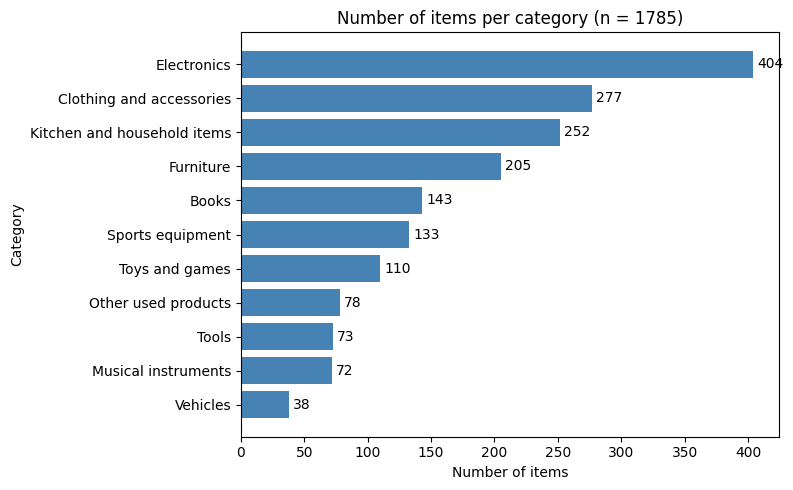

In [30]:
import matplotlib.pyplot as plt

# which categories are most common
counts = clean["category"].value_counts().sort_values()
plt.figure(figsize=(8, 5))
plt.barh(counts.index, counts.values, color="steelblue")
for i, v in enumerate(counts.values):
    plt.text(v + 3, i, str(v), va="center")
plt.title(f"Number of items per category (n = {counts.sum()})")
plt.xlabel("Number of items")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

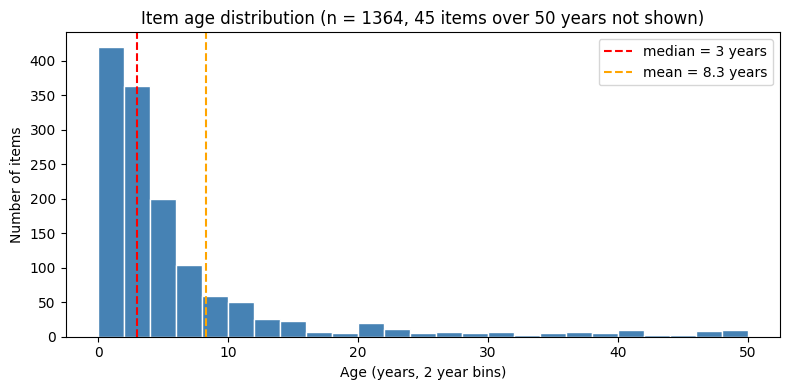

In [31]:
# age distribution, items over 50 years are left out of the plot so the rest is readable
ages = clean["age"].dropna()
shown = ages[ages <= 50]
plt.figure(figsize=(8, 4))
plt.hist(shown, bins=range(0, 52, 2), color="steelblue", edgecolor="white")
plt.axvline(ages.median(), color="red", linestyle="--", label=f"median = {ages.median():.0f} years")
plt.axvline(ages.mean(), color="orange", linestyle="--", label=f"mean = {ages.mean():.1f} years")
plt.title(f"Item age distribution (n = {len(shown)}, {len(ages) - len(shown)} items over 50 years not shown)")
plt.xlabel("Age (years, 2 year bins)")
plt.ylabel("Number of items")
plt.legend()
plt.tight_layout()
plt.show()

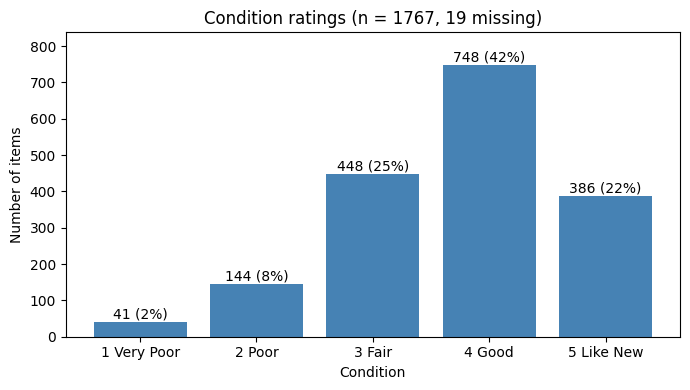

In [32]:
# which condition ratings are most common
cond = clean["condition"].value_counts().sort_index()
labels = ["1 Very Poor", "2 Poor", "3 Fair", "4 Good", "5 Like New"]
plt.figure(figsize=(7, 4))
plt.bar(labels, cond.values, color="steelblue")
for i, v in enumerate(cond.values):
    plt.text(i, v + 10, f"{v} ({v / cond.sum():.0%})", ha="center")
plt.ylim(0, cond.max() * 1.12)  # room for the labels
plt.title(f"Condition ratings (n = {cond.sum()}, {clean['condition'].isna().sum()} missing)")
plt.xlabel("Condition")
plt.ylabel("Number of items")
plt.tight_layout()
plt.show()

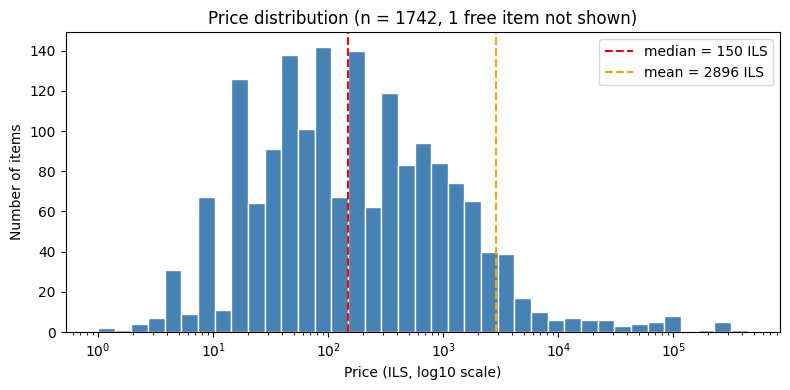

In [33]:
# price distribution, prices go from 1 to 442,800 ILS so a log scale is used
prices = clean["price_ils"].dropna()
free = (prices == 0).sum()
prices = prices[prices > 0]  # free items cant go on a log scale
plt.figure(figsize=(8, 4))
plt.hist(prices, bins=np.logspace(0, np.log10(prices.max()), 40), color="steelblue", edgecolor="white")
plt.xscale("log")
plt.axvline(prices.median(), color="red", linestyle="--", label=f"median = {prices.median():.0f} ILS")
plt.axvline(prices.mean(), color="orange", linestyle="--", label=f"mean = {prices.mean():.0f} ILS")
plt.title(f"Price distribution (n = {len(prices)}, {free} free item not shown)")
plt.xlabel("Price (ILS, log10 scale)")
plt.ylabel("Number of items")
plt.legend()
plt.tight_layout()
plt.show()

**What the univariate charts show**

- **Most common categories:** Electronics is the biggest group (404 items, 22.6%), then Clothing and accessories (277), Kitchen and household items (252) and Furniture (205). These 4 make up 64% of the data, while Tools, Musical instruments and Vehicles have under 75 items each. The categories are far from equal in size, so results for the small ones rest on fewer items
- **Item ages:** strongly right skewed. 70% of the items with an age are 5 years old or less and 373 are a year old or less, but a long tail of vintage items and 45 antiques over 50 years pull the mean (8.3 years) well above the median (3 years). The median describes a typical item better
- **Condition ratings:** 4 (Good) is the most common rating at 42%, and 64% of items are rated Good or Like New. Only 10% are Poor or Very Poor, so most second-hand items listed are in decent shape (or sellers rate their own items generously)
- **Prices:** they range from free to 442,800 ILS, so the raw scale is unreadable and a log scale is used. On the log scale the prices form a rough hill centred around 100-200 ILS. 81% of items cost under 1,000 ILS and only 49 cost 10,000 ILS or more, but those few push the mean to about 2,900 ILS against a median of 150 ILS. The spikes at 10, 50 and 100 ILS show that sellers like round prices

### C. Bivariate analysis

Two variables at a time. Prices are skewed, so groups are compared with **medians and boxplots** on a log scale, and relationships are measured with two correlations:

- **Pearson's r** (from the lectures) uses the raw values and assumes a straight-line relationship, so like the mean it gets pulled around by a few extreme prices
- **Spearman's r** is the same calculation done on the ranks (1st, 2nd, 3rd ...) instead of the values, so a 442,800 ILS guitar just counts as "the most expensive" and does not dominate. It also suits condition, which is a 1-5 score

Both are shown and Spearman is used for the conclusions. Rough guide for |r|: 0.1 small, 0.3 medium, 0.5 large.

In a boxplot the box is the middle half of the items (Q1 to Q3), the line inside is the median and the dots are outliers. These are patterns in this dataset only, they do not show that one thing causes the other.

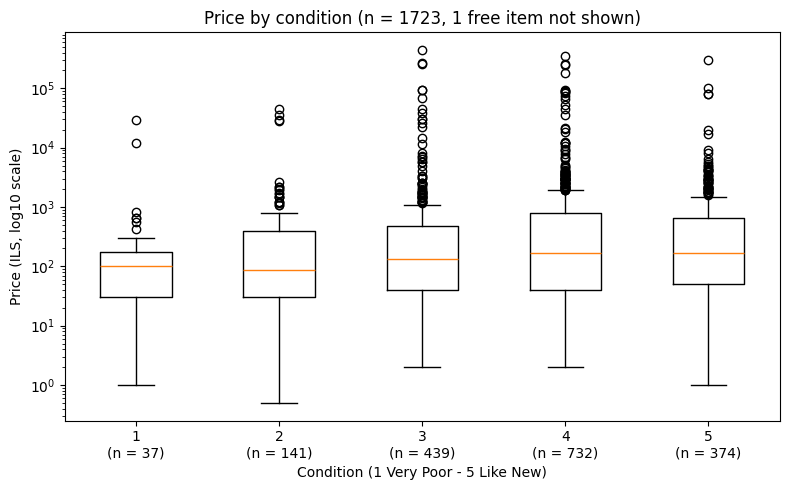

all items: pearson r = 0.00 | spearman r = 0.09 (n = 1724)
without vehicles: pearson r = -0.01 | spearman r = 0.10 (n = 1687)


,count,median
condition,,
1.0,37,100.0
2.0,141,86.0
3.0,439,131.0
4.0,733,164.0
5.0,374,170.0


In [34]:
# condition vs price, one box per condition rating
cp = clean.dropna(subset=["condition", "price_ils"])
cp_pos = cp[cp["price_ils"] > 0]  # free item cant go on a log scale
levels = [1, 2, 3, 4, 5]
groups = [cp_pos.loc[cp_pos["condition"] == c, "price_ils"] for c in levels]
plt.figure(figsize=(8, 5))
plt.boxplot(groups)
plt.xticks(range(1, 6), [f"{c}\n(n = {len(g)})" for c, g in zip(levels, groups)])
plt.yscale("log")
plt.title(f"Price by condition (n = {len(cp_pos)}, {len(cp) - len(cp_pos)} free item not shown)")
plt.xlabel("Condition (1 Very Poor - 5 Like New)")
plt.ylabel("Price (ILS, log10 scale)")
plt.tight_layout()
plt.show()

# pearson uses the raw prices, spearman uses their ranks so the huge prices count less
no_cars = cp[cp["category"] != "Vehicles"]
for name, data in [("all items", cp), ("without vehicles", no_cars)]:
    pearson = data["condition"].corr(data["price_ils"])
    spearman = data["condition"].corr(data["price_ils"], method="spearman")
    print(f"{name}: pearson r = {pearson:.2f} | spearman r = {spearman:.2f} (n = {len(data)})")
cp.groupby("condition")["price_ils"].agg(["count", "median"]).round(0)

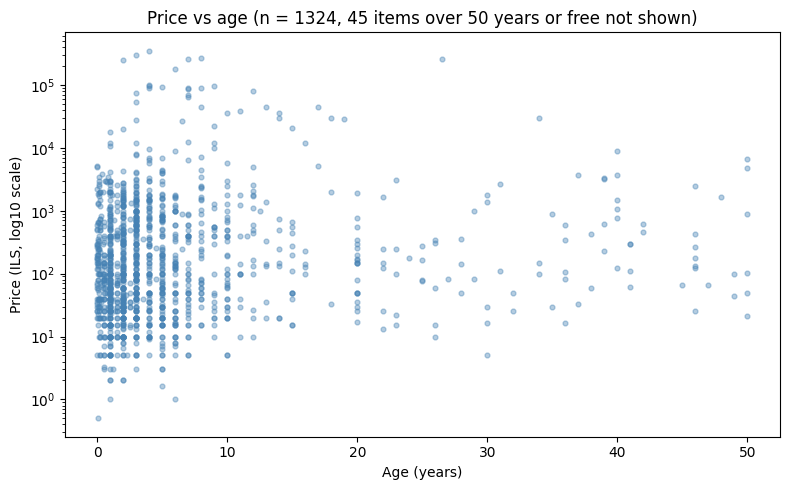

all items: pearson r = 0.06 | spearman r = 0.18 (n = 1369)
without vehicles: pearson r = 0.12 | spearman r = 0.15 (n = 1332)


,count,median
age,,
0-1,360,80.0
1-3,399,100.0
3-5,193,150.0
5-10,198,150.0
10-20,89,170.0
20-50,85,150.0
over 50,45,548.0


In [35]:
# age vs price, items over 50 years are left out of the plot only (not the numbers)
ap = clean.dropna(subset=["age", "price_ils"])
shown = ap[(ap["age"] <= 50) & (ap["price_ils"] > 0)]
plt.figure(figsize=(8, 5))
plt.scatter(shown["age"], shown["price_ils"], s=12, alpha=0.4, color="steelblue")
plt.yscale("log")
plt.title(f"Price vs age (n = {len(shown)}, {len(ap) - len(shown)} items over 50 years or free not shown)")
plt.xlabel("Age (years)")
plt.ylabel("Price (ILS, log10 scale)")
plt.tight_layout()
plt.show()

# pearson uses the raw prices, spearman uses their ranks so the huge prices count less
no_cars = ap[ap["category"] != "Vehicles"]
for name, data in [("all items", ap), ("without vehicles", no_cars)]:
    pearson = data["age"].corr(data["price_ils"])
    spearman = data["age"].corr(data["price_ils"], method="spearman")
    print(f"{name}: pearson r = {pearson:.2f} | spearman r = {spearman:.2f} (n = {len(data)})")

# median price for each age group
age_group = pd.cut(ap["age"], bins=[-1, 1, 3, 5, 10, 20, 50, 300],
                   labels=["0-1", "1-3", "3-5", "5-10", "10-20", "20-50", "over 50"])
ap.groupby(age_group, observed=True)["price_ils"].agg(["count", "median"]).round(0)

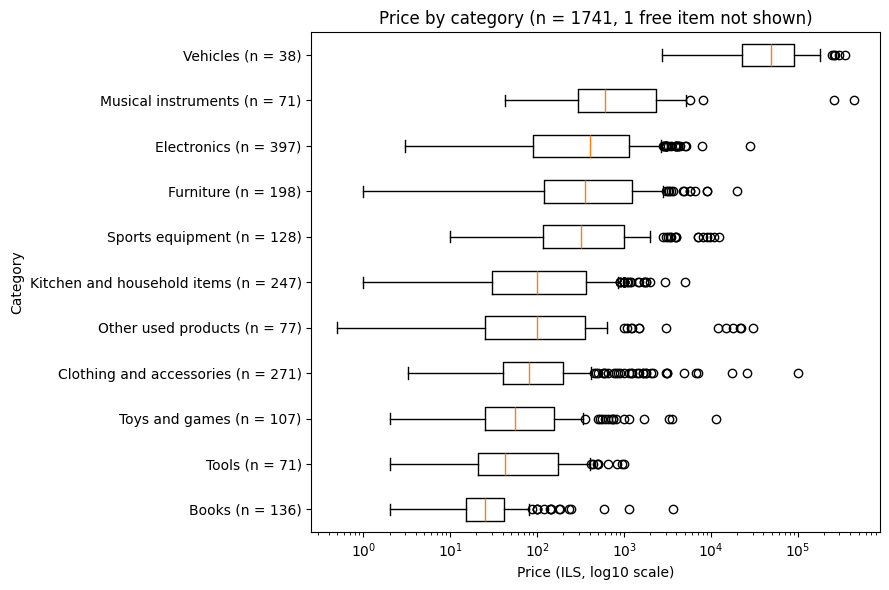

,count,median,mean
category,,,
Vehicles,38,49000.0,81075.0
Musical instruments,71,600.0,11220.0
Electronics,397,400.0,861.0
Furniture,198,350.0,985.0
Sports equipment,128,322.0,1118.0
Other used products,77,100.0,1767.0
Kitchen and household items,248,100.0,300.0
Clothing and accessories,271,80.0,819.0
Toys and games,107,56.0,322.0


In [36]:
# category vs price, categories sorted by median price
cat_p = clean.dropna(subset=["category", "price_ils"])
cat_pos = cat_p[cat_p["price_ils"] > 0]  # free item cant go on a log scale
order = cat_pos.groupby("category")["price_ils"].median().sort_values().index
groups = [cat_pos.loc[cat_pos["category"] == c, "price_ils"] for c in order]
plt.figure(figsize=(9, 6))
plt.boxplot(groups, vert=False)
plt.yticks(range(1, len(order) + 1), [f"{c} (n = {len(g)})" for c, g in zip(order, groups)])
plt.xscale("log")
plt.title(f"Price by category (n = {len(cat_pos)}, {len(cat_p) - len(cat_pos)} free item not shown)")
plt.xlabel("Price (ILS, log10 scale)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

cat_p.groupby("category")["price_ils"].agg(["count", "median", "mean"]).sort_values("median", ascending=False).round(0)

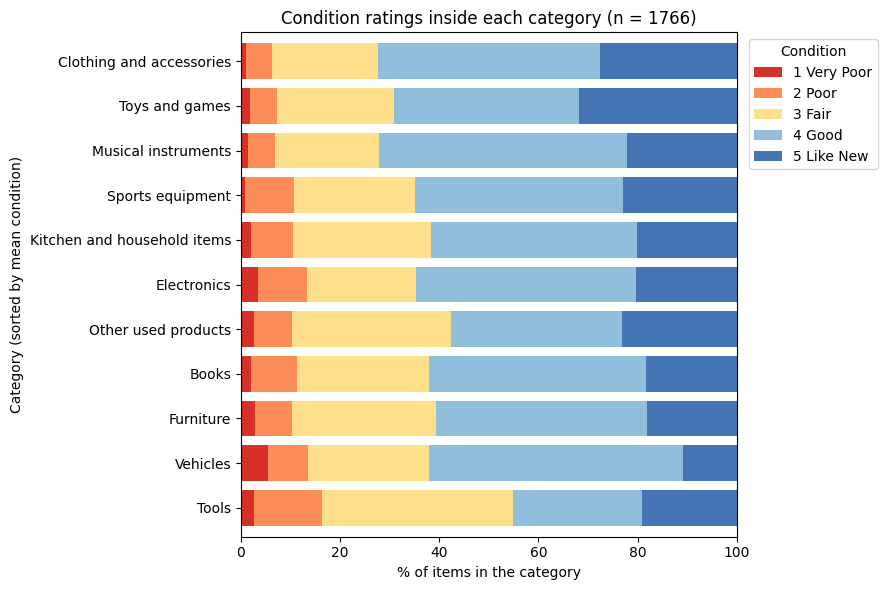

,count,median,mean
category,,,
Clothing and accessories,272,4.0,3.93
Toys and games,110,4.0,3.92
Musical instruments,72,4.0,3.86
Sports equipment,131,4.0,3.76
Kitchen and household items,248,4.0,3.69
Electronics,400,4.0,3.68
Other used products,78,4.0,3.68
Books,142,4.0,3.67
Furniture,203,4.0,3.66


In [37]:
# category vs condition, share of each rating inside each category
cc = clean.dropna(subset=["category", "condition"])
share = pd.crosstab(cc["category"], cc["condition"], normalize="index") * 100
share.columns = ["1 Very Poor", "2 Poor", "3 Fair", "4 Good", "5 Like New"]
share = share.loc[cc.groupby("category")["condition"].mean().sort_values().index]
colors = ["#d73027", "#fc8d59", "#fee08b", "#91bfdb", "#4575b4"]
share.plot(kind="barh", stacked=True, color=colors, figsize=(9, 6), width=0.8)
plt.title(f"Condition ratings inside each category (n = {len(cc)})")
plt.xlabel("% of items in the category")
plt.ylabel("Category (sorted by mean condition)")
plt.legend(title="Condition", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

cc.groupby("category")["condition"].agg(["count", "median", "mean"]).sort_values("mean", ascending=False).round(2)

In [38]:
# items are not independent (about 15 per student), so check if one student drives a correlation
# redo each spearman leaving out one student at a time
for col in ["condition", "age"]:
    pair = clean.dropna(subset=[col, "price_ils"])
    full = pair[col].corr(pair["price_ils"], method="spearman")
    without = {}
    for s in pair["student_id"].unique():
        rest = pair[pair["student_id"] != s]
        without[s] = rest[col].corr(rest["price_ils"], method="spearman")
    without = pd.Series(without)
    print(f"{col} vs price: r = {full:.2f}, leaving out one student it goes from "
          f"{without.min():.2f} (without {without.idxmin()}) to {without.max():.2f} (without {without.idxmax()})")

# how many students each category comes from, and the share of the biggest one
top_share = clean.groupby("category")["student_id"].agg(lambda s: s.value_counts().iloc[0] / len(s) * 100)
spread = pd.DataFrame({
    "items": clean["category"].value_counts(),
    "students": clean.groupby("category")["student_id"].nunique(),
    "top student %": top_share.round(1),
})
spread.sort_values("top student %", ascending=False)

condition vs price: r = 0.09, leaving out one student it goes from 0.09 (without 1230110) to 0.10 (without 1231612)
age vs price: r = 0.18, leaving out one student it goes from 0.17 (without 1230014) to 0.20 (without 1230019)


,items,students,top student %
category,,,
Vehicles,38,20,13.2
Other used products,78,43,10.3
Musical instruments,72,46,6.9
Tools,73,43,6.8
Toys and games,110,66,3.6
Clothing and accessories,277,102,3.2
Sports equipment,133,70,3.0
Books,143,76,2.8
Electronics,404,116,2.5


**What the bivariate analysis shows**

- **Condition and price** (Spearman r = 0.09, n = 1,724): a very weak link. The median price goes from about 90-100 ILS for conditions 1-2 to 131 ILS for 3 and about 170 ILS for 4-5, so better condition items tend to cost a bit more, but the boxes overlap almost completely. Without vehicles Spearman r is 0.10, so it is not just the cars. Condition alone says little about price because the categories are mixed together (a poor laptop still costs more than a like new book), which is checked in 4D
- **Age and price** (r = 0.18, n = 1,369): a small positive link, the opposite of "older means cheaper". Items under a year old have the lowest median (80 ILS), items 3-20 years old sit around 150-170 ILS and the 45 items over 50 years have a median of 548 ILS. A likely reason is that the newest items are cheap everyday things, while old items that are still being sold are often furniture, instruments or antiques that keep their value. This is an exploratory pattern, not proof that age adds value
- **Pearson vs Spearman:** Pearson gives 0.00 for condition and 0.06 for age, and for age it doubles to 0.12 just by removing the 38 vehicles. A handful of very expensive items (cars, the 1954 guitar, antiques) decide the Pearson value, the same way they pull the mean away from the median. Spearman stays steady (0.09 and 0.18) and matches what the boxplots show, so it is the one used for the conclusions
- **Category and price:** category is linked to price much more strongly than condition or age. Medians range from 25 ILS (Books) and 42 ILS (Tools) to 600 ILS (Musical instruments) and 49,000 ILS (Vehicles). In every category the mean is well above the median (eg Musical instruments: mean 11,220 vs median 600, because of the 1954 Fender guitar and a Fazioli piano), so medians are used to compare them
- **Category and condition:** fairly similar across categories, the median rating is 4 (Good) everywhere except Tools (3). Clothing and accessories (mean 3.93) and Toys and games (3.92) are rated best, Tools are rated worst (mean 3.45, about 16% Poor or Very Poor). Vehicles have the largest share of Very Poor items (5%)
- **One student driving a pattern?** No. Leaving out any single student changes r by at most 0.02 for both condition and age. No category is dominated by one student either, the biggest share is 13.2% (5 of the 38 vehicles from one student), and every other category is at 10.3% or less

### D. Multivariate analysis

Three variables at a time, to see if a relationship from 4C changes once a third variable is taken into account:

1. Does the link between condition and price differ across categories?
2. Are older items in good condition priced differently from older items in poor condition? Items are split into 3 age groups (up to 2, 2 to 10, over 10 years) and 3 condition groups (poor 1-2, fair 3, good 4-5), and the median price is compared in each box of that grid
3. A correlation heatmap of age, condition and price, with Pearson and Spearman side by side

Same rules as 4C: medians, log scales for price, Spearman for the conclusions.

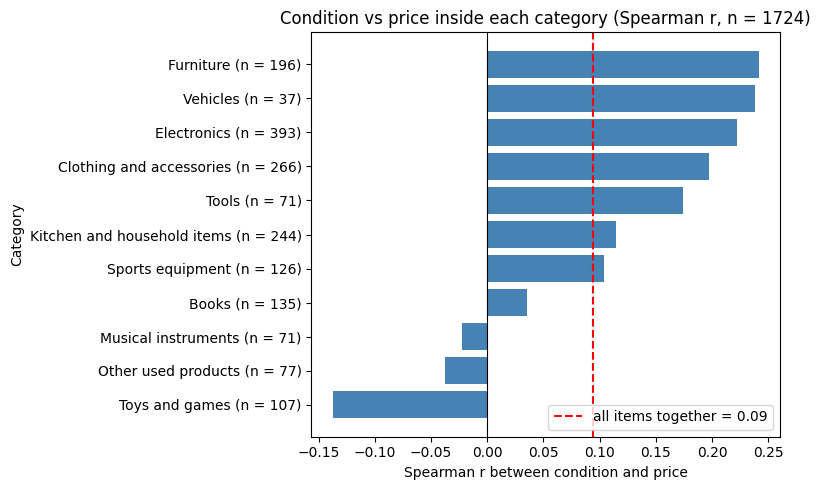

,n,pearson r,spearman r,median poor (1-2),median fair (3),median good (4-5)
category,,,,,,
Toys and games,107,-0.13,-0.14,78.69,108.30,49.20
Other used products,77,-0.07,-0.04,286.20,55.00,100.00
Musical instruments,71,-0.16,-0.02,426.24,1077.50,550.00
Books,135,0.05,0.04,35.00,20.00,25.00
Sports equipment,126,0.12,0.10,103.15,350.00,325.62
Kitchen and household items,244,0.16,0.11,50.00,130.00,100.00
Tools,71,0.17,0.17,32.80,41.08,55.00
Clothing and accessories,266,0.07,0.20,60.00,60.00,82.00
Electronics,393,0.07,0.22,130.58,260.50,550.00


In [39]:
# condition vs price inside each category
rows = []
for cat, g in cp.groupby("category"):
    rows.append({
        "category": cat,
        "n": len(g),
        "pearson r": g["condition"].corr(g["price_ils"]),
        "spearman r": g["condition"].corr(g["price_ils"], method="spearman"),
        "median poor (1-2)": g.loc[g["condition"] <= 2, "price_ils"].median(),
        "median fair (3)": g.loc[g["condition"] == 3, "price_ils"].median(),
        "median good (4-5)": g.loc[g["condition"] >= 4, "price_ils"].median(),
    })
by_cat = pd.DataFrame(rows).set_index("category").sort_values("spearman r")
overall = cp["condition"].corr(cp["price_ils"], method="spearman")

plt.figure(figsize=(8, 5))
plt.barh([f"{c} (n = {n})" for c, n in zip(by_cat.index, by_cat["n"])], by_cat["spearman r"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(overall, color="red", linestyle="--", label=f"all items together = {overall:.2f}")
plt.title(f"Condition vs price inside each category (Spearman r, n = {len(cp)})")
plt.xlabel("Spearman r between condition and price")
plt.ylabel("Category")
plt.legend()
plt.tight_layout()
plt.show()

by_cat.round(2)

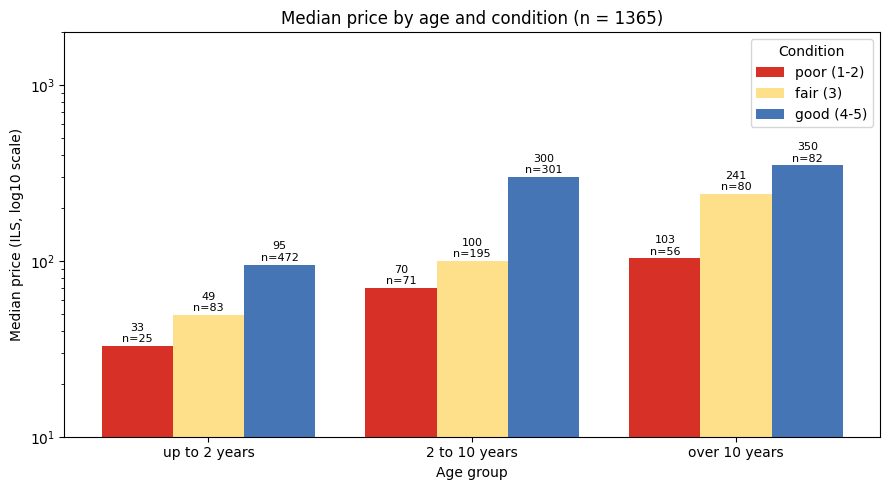

age vs condition: spearman r = -0.42
up to 2 years: condition vs price spearman r = 0.16 (n = 580)
2 to 10 years: condition vs price spearman r = 0.19 (n = 567)
over 10 years: condition vs price spearman r = 0.23 (n = 218)


condition group,poor (1-2),fair (3),good (4-5)
age group,,,
up to 2 years,33.0,49.0,95.0
2 to 10 years,70.0,100.0,300.0
over 10 years,103.0,241.0,350.0


In [40]:
# age group x condition group, median price in each box
acp = clean.dropna(subset=["age", "condition", "price_ils"]).copy()
acp["age group"] = pd.cut(acp["age"], bins=[-1, 2, 10, 300],
                          labels=["up to 2 years", "2 to 10 years", "over 10 years"])
acp["condition group"] = pd.cut(acp["condition"], bins=[0, 2, 3, 5],
                                labels=["poor (1-2)", "fair (3)", "good (4-5)"])
medians = acp.pivot_table(index="age group", columns="condition group", values="price_ils",
                          aggfunc="median", observed=True)
counts = acp.pivot_table(index="age group", columns="condition group", values="price_ils",
                         aggfunc="count", observed=True)

# grouped bars, one group per age, one bar per condition
x = np.arange(len(medians.index))
colors = ["#d73027", "#fee08b", "#4575b4"]
plt.figure(figsize=(9, 5))
for i, cond in enumerate(medians.columns):
    plt.bar(x + (i - 1) * 0.27, medians[cond], width=0.27, color=colors[i], label=cond)
    for xi, (m, n) in enumerate(zip(medians[cond], counts[cond])):
        plt.text(xi + (i - 1) * 0.27, m * 1.05, f"{m:.0f}\nn={n}", ha="center", fontsize=8)
plt.xticks(x, medians.index)
plt.yscale("log")
plt.ylim(10, 2000)
plt.title(f"Median price by age and condition (n = {len(acp)})")
plt.xlabel("Age group")
plt.ylabel("Median price (ILS, log10 scale)")
plt.legend(title="Condition")
plt.tight_layout()
plt.show()

# condition vs price again, but only comparing items of a similar age
print(f"age vs condition: spearman r = {acp['age'].corr(acp['condition'], method='spearman'):.2f}")
for grp, g in acp.groupby("age group", observed=True):
    print(f"{grp}: condition vs price spearman r = {g['condition'].corr(g['price_ils'], method='spearman'):.2f} (n = {len(g)})")
medians.round(0)

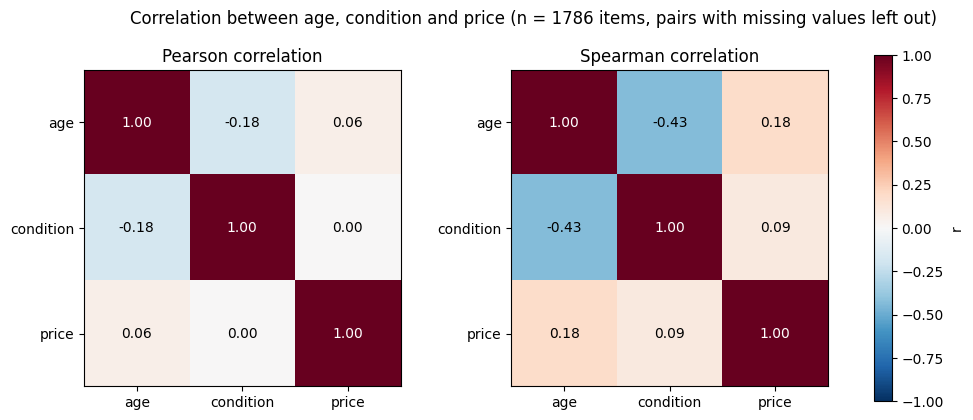

,age,condition,price_ils
age,1.00,-0.43,0.18
condition,-0.43,1.00,0.09
price_ils,0.18,0.09,1.00


In [41]:
# correlation heatmaps, each pair uses the items that have both values
num_cols = ["age", "condition", "price_ils"]
labels = ["age", "condition", "price"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = clean[num_cols].corr(method=method)
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(3))
    ax.set_xticklabels(labels)
    ax.set_yticks(range(3))
    ax.set_yticklabels(labels)
    for i in range(3):
        for j in range(3):
            r = corr.iloc[i, j]
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", color="white" if abs(r) > 0.5 else "black")
    ax.set_title(f"{method.capitalize()} correlation")
fig.subplots_adjust(wspace=0.35)
fig.colorbar(im, ax=axes, label="r")
fig.suptitle(f"Correlation between age, condition and price (n = {len(clean)} items, pairs with missing values left out)")
plt.show()

clean[num_cols].corr(method="spearman").round(2)

**What the multivariate analysis shows**

- **The condition and price link depends on the category.** Inside Furniture (Spearman r = 0.24), Electronics (0.22), Clothing and accessories (0.20) and Vehicles (0.24, only 37 items) better condition items tend to cost clearly more, eg in Electronics the median goes from 261 ILS for fair items to 550 ILS for good ones. In Books (0.04) condition barely matters, and in Musical instruments (-0.02) and Toys and games (-0.14) the link is slightly negative: fair instruments have a higher median (1,078 ILS) than good ones (550 ILS), probably because vintage pieces like the 1954 Fender are rated fair but are worth a lot. So the weak overall r of 0.09 hides a stronger link in some categories and none in others. The poor groups inside each category are small (5 to 52 items), so these per-category numbers are rough
- **Older items in good condition are priced very differently from older items in poor condition.** For items over 10 years old, the median is 350 ILS in good condition against 103 ILS in poor condition, more than 3 times higher. The same gap shows up in every age group (98 vs 33 ILS for items up to 2 years, 300 vs 70 ILS for 2 to 10 years)
- **Why condition looked weak in 4C:** age and condition are linked (Spearman r = -0.43, a medium link, the strongest one in the heatmap), older items tend to be in worse condition, but older items also tend to cost more (r = 0.18). Mixing all ages together cancels part of the condition effect out. When only items of a similar age are compared, the condition and price link goes up from 0.09 to 0.16-0.23
- **Heatmap:** with Spearman, the only medium link is age and condition (-0.43), the links with price are small (0.18 and 0.09). Pearson shows almost nothing (0.06 and 0.00) because a few huge prices control it, same as in 4C
- These are exploratory patterns, the groups still mix categories (old items include antiques and furniture), and some boxes are small (25 poor items up to 2 years old), so they show what tends to happen in this dataset, not what causes prices

## 5. Insight Discovery

Five insights from the analysis above. Each one gives the pattern, the evidence (from the tables and charts in Section 4 or the numbers below), what it means, and what it implies for the second-hand marketplace. They are exploratory, so they describe what tends to happen in this dataset, not what causes it.

In [42]:
# extra numbers for the insights
prices = clean["price_ils"].dropna().sort_values(ascending=False)
top1 = round(len(prices) * 0.01)
top10 = round(len(prices) * 0.10)
print(f"mean / median: {prices.mean() / prices.median():.1f}")
print(f"top 1% of items ({top1}) hold {prices.head(top1).sum() / prices.sum():.0%} of the total listed value")
print(f"top 10% of items ({top10}) hold {prices.head(top10).sum() / prices.sum():.0%} of the total listed value")

# round prices, checked on the original ILS prices since converting breaks round numbers
ils = clean.loc[(clean["currency"] == "ILS") & (clean["price"] > 0), "price"]
for step in [10, 50, 100]:
    print(f"ILS prices that are a multiple of {step}: {(ils % step == 0).mean():.0%} (n = {len(ils)})")
print(f"ILS prices ending in 9: {(ils % 10 == 9).mean():.1%}")
ils.value_counts().head(5)

mean / median: 19.3
top 1% of items (17) hold 62% of the total listed value
top 10% of items (174) hold 90% of the total listed value
ILS prices that are a multiple of 10: 82% (n = 1196)
ILS prices that are a multiple of 50: 51% (n = 1196)
ILS prices that are a multiple of 100: 36% (n = 1196)
ILS prices ending in 9: 0.6%


price
20.0     66
10.0     56
100.0    55
50.0     52
30.0     48
Name: count, dtype: int64

### Insight 1: A handful of items control the price data

- **Pattern:** prices are extremely right skewed. A typical item costs about 150 ILS, but the mean is 2,895 ILS, about 19 times the median
- **Evidence:** the top 1% of items (17 items, mostly cars and collector pieces) hold 62% of the total listed value, and the top 10% hold 90% (cell above). The std (21,587) is far bigger than the IQR (610) in 4A, and the 4B histogram only looks normal on a log scale
- **What it means:** the "average price" of this marketplace describes a few cars and antiques, not the items most people list. The median and IQR describe a typical item, and this is also why Pearson gave values close to 0 in 4C and 4D
- **Implication:** any price guide or summary for a second-hand marketplace should use medians and price ranges per category. An average would tell a normal seller that their items are worth far more than they really are

### Insight 2: Category is linked to price much more than condition or age

- **Pattern:** the type of item is linked to its price far more than its age or condition
- **Evidence:** the median price goes from 25 ILS (Books) and 42 ILS (Tools) up to 600 ILS (Musical instruments) and 49,000 ILS (Vehicles) in the 4C category boxplot, while condition (Spearman r = 0.09) and age (r = 0.18) only have weak links with price
- **What it means:** items in the same category tend to share a price range, and condition and age only go with smaller differences inside that range
- **Implication:** a marketplace that suggests prices or shows "similar items" should always compare inside the same category, since comparing a book with a laptop says nothing about whether either is fairly priced

### Insight 3: Condition is linked to price once age is taken into account

- **Pattern:** across all items condition looks almost unrelated to price, but among items of a similar age, better condition is clearly linked to a higher price
- **Evidence:** overall Spearman r = 0.09, but age and condition are linked (r = -0.43), and inside each age group the condition and price link goes up to 0.16-0.23 (4D). For items over 10 years old, the median is 350 ILS in good condition against 103 ILS in poor condition, more than 3 times higher, and the same gap shows up for items up to 2 years (98 vs 33 ILS) and 2 to 10 years (300 vs 70 ILS)
- **What it means:** older items tend to be in worse condition but also tend to cost more, so when all ages are mixed the two links partly cancel out. The condition and price link is there, it is just hidden when ages are mixed. The link is also clearer in some categories (Furniture, Electronics, Clothing) than others (Books, Musical instruments)
- **Implication:** items in good condition tend to be listed at higher prices, especially older items, so buyers comparing prices should compare items of a similar age and category. A pricing model should use age and condition together, not one at a time

### Insight 4: Older items are not cheaper in this market

- **Pattern:** price tends to go up with age, not down (Spearman r = 0.18), which is the opposite of normal depreciation
- **Evidence:** items up to a year old have the lowest median price (80 ILS), items 3 to 20 years old sit around 150-170 ILS, and the 45 items older than 50 years have a median of 548 ILS (4C age groups and scatterplot)
- **What it means:** the newest items in the data are mostly cheap everyday products, while the old items that people still sell are often furniture, instruments, vintage pieces and antiques that keep or gain value. So age alone does not tell you how much value an item lost
- **Implication:** sellers should not discount an item just because it is old, and vintage and antique items behave like a separate niche with their own pricing

### Insight 5: Sellers price in round numbers

- **Pattern:** second-hand prices pile up on round values instead of being spread smoothly
- **Evidence:** 82% of the prices given in ILS are a multiple of 10, 51% are a multiple of 50 and 36% are a multiple of 100, while only 0.6% end in 9 (cell above). The most common prices are 20, 10, 100 and 50 ILS, which are the spikes in the 4B price histogram
- **What it means:** people selling used items estimate a fair price rather than calculate one, and the "9.99" style of pricing used in shops is almost never used here
- **Implication:** listed prices are rough starting points, so there is likely room to negotiate. For analysis, small price differences (like 95 vs 100 ILS) should not be read as real differences in value

## 6. Limitations and Reflection

The results above come with some limits on how far they can be trusted. The numbers below back up the limitations that can be measured.

In [ ]:
# numbers for the limitations
age_missing = clean.groupby("student_id")["age"].apply(lambda s: s.isna().mean())
print(f"age missing: {clean['age'].isna().sum()} items ({clean['age'].isna().mean():.1%})")
print("students with at least one missing age:", (age_missing > 0).sum(), "| with all ages missing:", (age_missing == 1).sum())

# rounded ages are a sign the age was guessed
ages = clean["age"].dropna()
old = ages[ages >= 5]
print(f"ages that are whole numbers: {(ages % 1 == 0).mean():.0%} (n = {len(ages)})")
print(f"items 5+ years old with an age that is a multiple of 5: {(old % 5 == 0).mean():.0%} (n = {len(old)})")

# each student uses the condition scale their own way
student_cond = clean.groupby("student_id")["condition"].mean()
print(f"mean condition per student: {student_cond.min():.2f} to {student_cond.max():.2f}")

counts = clean["category"].value_counts()
print("biggest / smallest category:", counts.idxmax(), counts.max(), "/", counts.idxmin(), counts.min())
has_cur = clean["currency"].notna()
print(f"prices not in ILS: {(clean.loc[has_cur, 'currency'] != 'ILS').mean():.0%} (n = {has_cur.sum()})")


### Limitations

1. **Missing information:** age is missing for 377 items (21.1%). 62 of the 120 students left at least one age blank and 3 left all of them blank. So every age result is based on 1,409 items, and if the items without an age are different (eg older items whose age the seller didn't know), the age results could be off. 43 items also have no price in ILS and are left out of the price analysis
2. **Unequal categories:** Electronics has 404 items but Vehicles only 38, more than 10 times fewer, and Tools and Musical instruments have about 70 each. Results for the small categories rest on few items, and once they are split further the groups get very small (eg 5 to 52 poor items per category in 4D, 25 poor items up to 2 years old)
3. **Subjective condition ratings:** each student rated their own items on the 1-5 scale with no written definition of each level. The mean rating per student goes from 2.60 to 4.67, which is partly because they listed different items, but also shows that people use the scale differently. 64% of items are rated Good or Like New, so the ratings may be generous
4. **Estimated item ages:** 83% of ages are whole numbers, and 40% of items 5 years or older have an age that is a multiple of 5 (5, 10, 15 ...), about double what an even spread would give. This shows that many ages are rough guesses, so small age differences (like 4 vs 5 years) should not be taken too seriously
5. **Items are not independent and not a random sample:** each student entered about 15 items they chose themselves, some from their own home and some from online listings, and 11 listings were collected by more than one student (Section 3). The leave-one-out check in 4C showed that no single student drives the main results, but the data is still not a random sample of the second-hand market, so the results describe this dataset and may not hold for the whole market
6. **Listed prices, not sale prices:** the prices are what sellers asked for, not what the items actually sold for. 31% of prices were in another currency and were converted with one fixed rate (20 Nov 2026), and the rates for 9 small currencies are approximate, so they also mix prices from different countries and markets

### Improvements for future data collection

1. **One fixed template for everyone:** the same file type and column names, a dropdown for category (including Vehicles), price always in ILS, and age always as a number of years. Most of the cleaning in Section 3 (30 column name spellings, 97 category spellings, text ages and conditions) would not have been needed
2. **A written definition for each condition level:** eg 5 = no visible wear, 3 = works but has clear marks, 1 = damaged or needs repair, with an example photo for each. This would make the ratings from different students comparable
3. **An "age is estimated" column and a source column:** a yes/no column for estimated ages, so exact and guessed ages can be separated, and a column for where the item came from (own item, or the link to the online listing). The listing link would make duplicates easy to find, since 11 groups of duplicates had to be found by hand here
4. **Balanced categories:** ask each student for items from several fixed categories (eg at least 1 per category) so the small categories get enough items to compare

### Reflection

Most of the work in this assignment was integration and cleaning, not the analysis itself. 120 students following the same instructions still produced files in different formats, column names, currencies and spellings, and some of the same listings. Checking things by hand (the old items, the duplicates in Arabic, the photos) found problems that the simple rules missed, like the 1924 book and the 2024 Jeep. The analysis also showed that for skewed data like second-hand prices, the median, the IQR and Spearman give a much clearer picture than the mean and Pearson, and that a weak link between two variables can hide a stronger one once a third variable (like age) is taken into account.